In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)
from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson

import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from matplotlib import font_manager
font_manager.fontManager.addfont("../../../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 18,
    "pdf.fonttype": 42,       # Embed TrueType fonts in PDF
})

/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


0 -85419.8782643705 -0.006829971500657596
83.43444 20.540688
max 83.43444
cluster 0 done
1 -183051.44330258892 0.003598443685060471
83.248604 4.207502
max 83.248604
cluster 1 done
2 -233786.7235916928 0.00492844561862209
89.95197 4.102275
max 89.95197
cluster 2 done
3 -263489.1592020005 -0.0044142745121887655
120.78182 3.7287495
max 120.78182
cluster 3 done
4 -223506.85330896205 0.0015875248971233189
102.23698 4.1970644
max 102.23698
cluster 4 done
5 -256890.26334484905 -0.006838529131668065
106.80745 4.0165153
max 106.80745
cluster 5 done
6 -155613.83505023335 0.0021841466005273883
139.31015 4.337413
max 139.31015
cluster 6 done
7 -173094.14032947153 -0.006881421189092249
158.09642 12.355805
max 158.09642
cluster 7 done
8 -208691.29348852785 0.006467353799680505
122.717766 4.1725388
max 122.717766
cluster 8 done
9 -168332.15575540098 0.0026763637034363562
110.137146 4.2183046
max 110.137146
cluster 9 done
10 -264409.52164410637 0.003681454928538454
119.75524 4.1481733
max 119.75524
cl

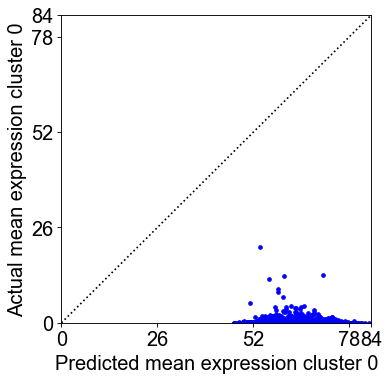

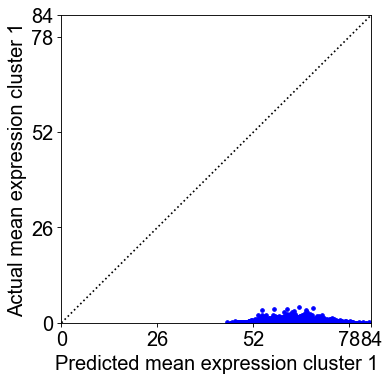

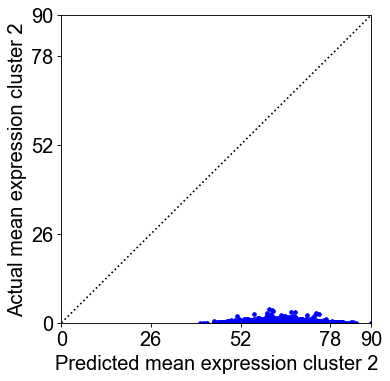

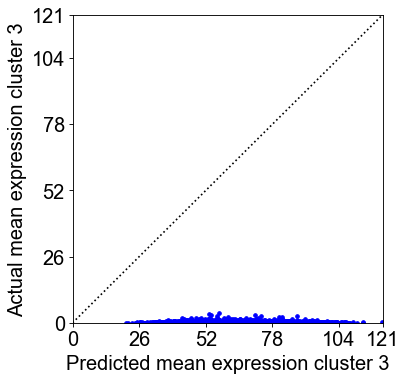

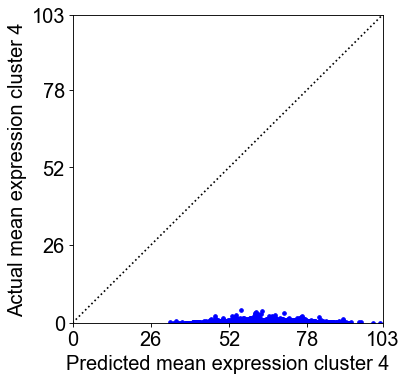

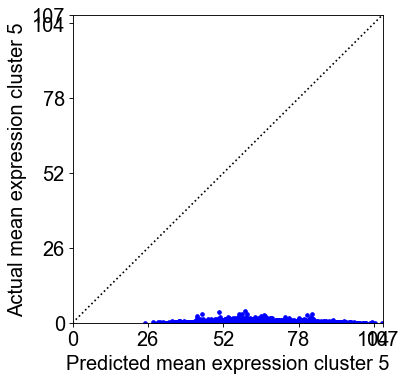

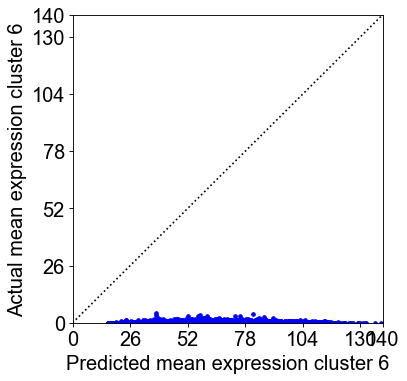

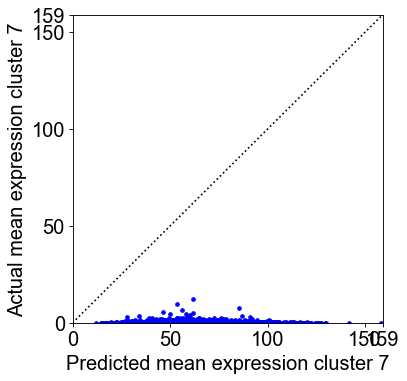

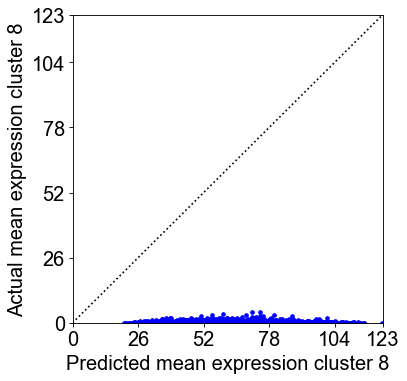

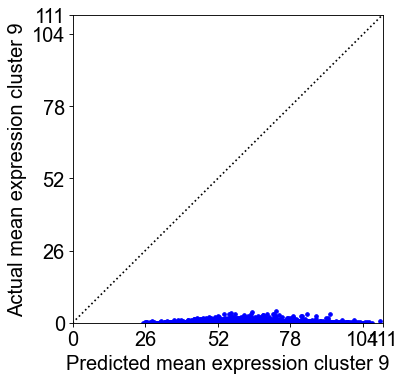

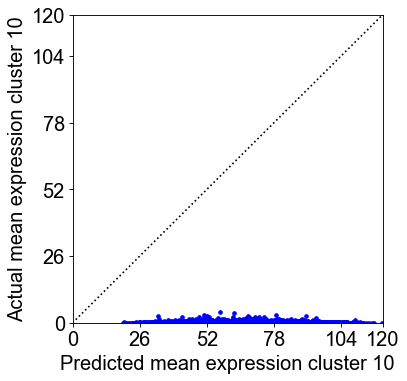

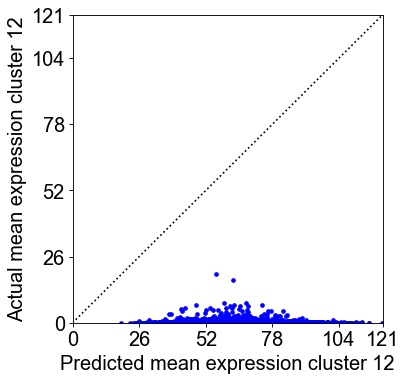

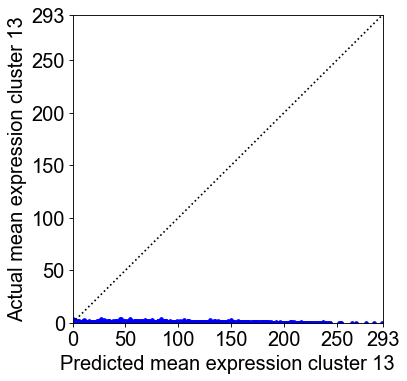

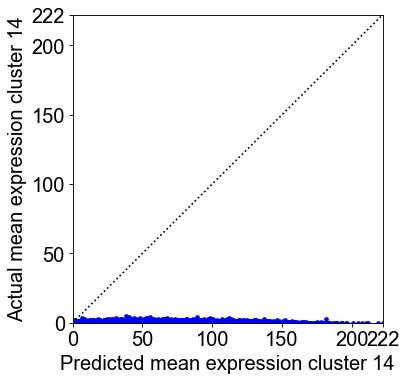

In [2]:

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
r_all = []
pearsonr_all = []
# print(predict_data)
# print(real_data)

# real_data_x = real_data.X if isinstance(real_data.X, np.ndarray) else real_data.X.toarray()
# real_data_tensor = torch.tensor(real_data_x, dtype=torch.float32)
# predict_data_x = predict_data.X if isinstance(predict_data.X, np.ndarray) else predict_data.X.toarray()
# predict_data_tensor = torch.tensor(predict_data_x, dtype=torch.float32)
# print(real_data_tensor.shape)
# print(predict_data_tensor.shape)
# print(real_data.shape)
for i in range(15):
  if i ==11:
    continue
  real_data = sc.read_h5ad(f"../../input/exp2_test_day21_cluster_{i}.h5ad")
  predict_data = sc.read_h5ad(f"../experiments/plant_exp2_squidiff_train_log_cluster_{i}/exp2_predict_day12_to_day21_cluster_{i}.h5ad")

  # predict_data = sc.read_h5ad(f"../experiments/plants_experiment1_predict_day21_cluster{i}_fixed/interception_predict_to_day_21.h5ad")
  r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
  print(i, r2, pearsonr)
  # r2_new, pearson_new = calc_r2_pearson(predict_data, real_data)
  # print(r2_new, pearson_new)
  r_all.append(['new method', f"cluster{i}", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'r2_score:',r2])
  pearsonr_all.append(['new method', f"cluster{i}", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'pearson_score:',pearsonr])


  pd.DataFrame(r_all).to_csv(os.path.join("squidiff_plant_exp2_r_all.csv"))
  pd.DataFrame(pearsonr_all).to_csv(os.path.join("squidiff_plant_exp2_pearsonr_all.csv"))

  fig, ax = plt.subplots(1,1,figsize=(5,5),dpi=80)
  plt.scatter(predict,
              real,
              s=10,
              c='blue'
            )
  limit = np.ceil(max(np.max(predict), np.max(real)))
  print(np.max(predict),np.max(real))
  plt.plot([0, limit], [0, limit], color="black", linestyle=":")
  plt.xlim([0, limit])
  plt.ylim([0, limit])
  if limit <= 8:
    ticks = np.arange(0, limit + 1, 1)
  elif limit <= 150:    
    ticks = np.arange(0, limit + 1, 26)
  else:
    ticks = np.arange(0, limit + 1, 50)
  ticks = np.append(ticks, limit)
  ticks = np.unique(ticks)
  plt.xticks(ticks)
  plt.yticks(ticks)
  print("max",max(np.max(predict), np.max(real)))
  plt.xlabel(f"Predicted mean expression cluster {i}")
  plt.ylabel(f"Actual mean expression cluster {i}")
  print(f"cluster {i} done")
  # fig.savefig(os.path.join("fig2.png"), bbox_inches="tight")
  fig.savefig(os.path.join(f"pred_with_actual_exp2_squidiff_cluster_{i}.pdf"), bbox_inches="tight")
# cal = calc_r2_pearson(adata_day2_predicted, adata_day2_actual)
# print(f'CAL metric: {cal}')